# Student Performance Prediction and Academic Risk Analysis
SEC C | Models: Linear Regression, Logistic Regression, KNN, K-Means

**Before running:** upload `student_performance_data.csv` when the second cell asks.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, os, warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, silhouette_score)

RS = 42
sns.set_style("whitegrid")

In [ ]:
if not os.path.exists("student_performance_data.csv"):
    from google.colab import files
    print("Please choose student_performance_data.csv ...")
    files.upload()

df = pd.read_csv("student_performance_data.csv")
print("Shape:", df.shape)
display(df.head())
df.info()

Shape: (500, 12)


,Student_ID,Gender,Attendance_Percentage,Study_Hours_Per_Week,Sleep_Hours,Previous_Marks,Assignment_Marks,Internal_Marks,Parental_Support,Internet_Access,Extracurricular,Final_Exam_Marks
0,STU0001,Male,76.9,15.3,6.3,54.9,51.1,52.1,High,Yes,No,41.2
1,STU0002,Female,56.9,1.9,6.3,41.1,21.0,17.8,Medium,Yes,No,20.9
2,STU0003,Female,60.4,13.5,6.4,15.2,33.7,42.5,High,Yes,No,21.3
3,STU0004,Male,100.0,10.8,8.2,75.8,79.5,59.7,Medium,Yes,Yes,51.8
4,STU0005,Male,62.6,4.4,7.7,22.2,20.1,32.9,Medium,Yes,Yes,26.8


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Student_ID             500 non-null    object 
 1   Gender                 500 non-null    object 
 2   Attendance_Percentage  500 non-null    float64
 3   Study_Hours_Per_Week   500 non-null    float64
 4   Sleep_Hours            500 non-null    float64
 5   Previous_Marks         500 non-null    float64
 6   Assignment_Marks       500 non-null    float64
 7   Internal_Marks         500 non-null    float64
 8   Parental_Support       500 non-null    object 
 9   Internet_Access        500 non-null    object 
 10  Extracurricular        500 non-null    object 
 11  Final_Exam_Marks       500 non-null    float64
dtypes: float64(7), object(5)
memory usage: 47.0+ KB


**Columns**
`Student_ID`, `Gender`, `Attendance_Percentage`, `Study_Hours_Per_Week`, `Sleep_Hours`, `Previous_Marks`, `Assignment_Marks`, `Internal_Marks`, `Parental_Support`, `Internet_Access`, `Extracurricular`, and the target **`Final_Exam_Marks`** (out of 100).
Pass mark = **40**.

In [ ]:
print("Missing values before cleaning:\n", df.isnull().sum()[df.isnull().sum() > 0], "\n")
print("Duplicate rows:", df.duplicated().sum())

# 1) remove duplicates
df = df.drop_duplicates().reset_index(drop=True)

# 2) invalid values (marks / attendance must be between 0 and 100) -> treat as missing
pct_cols = ["Attendance_Percentage", "Previous_Marks", "Assignment_Marks", "Internal_Marks", "Final_Exam_Marks"]
for c in pct_cols:
    bad = ((df[c] < 0) | (df[c] > 100)).sum()
    df.loc[(df[c] < 0) | (df[c] > 100), c] = np.nan
    if bad: print(f"{c}: {bad} invalid value(s) set to missing")

# 3) rows without target cannot be used
df = df.dropna(subset=["Final_Exam_Marks"])

# 4) fill missing values: median for numeric, mode for categorical
num_cols = ["Attendance_Percentage", "Study_Hours_Per_Week", "Sleep_Hours", "Previous_Marks", "Assignment_Marks", "Internal_Marks"]
cat_cols = ["Gender", "Parental_Support", "Internet_Access", "Extracurricular"]
for c in num_cols: df[c] = df[c].fillna(df[c].median())
for c in cat_cols: df[c] = df[c].fillna(df[c].mode()[0])

# 5) outliers: cap with the IQR rule
def cap_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return s.clip(q1 - 1.5*iqr, q3 + 1.5*iqr)
for c in ["Study_Hours_Per_Week", "Sleep_Hours"]:
    before = df[c].max(); df[c] = cap_outliers(df[c])
    print(f"{c}: max {before:.1f} -> {df[c].max():.1f}")

# 6) encode categorical data
df["Gender"] = df["Gender"].map({"Male": 0, "Female": 1})
df["Parental_Support"] = df["Parental_Support"].map({"Low": 0, "Medium": 1, "High": 2})
df["Internet_Access"] = df["Internet_Access"].map({"No": 0, "Yes": 1})
df["Extracurricular"] = df["Extracurricular"].map({"No": 0, "Yes": 1})

# 7) classification target: Pass (1) if final marks >= 40
PASS_MARK = 40
df["Pass_Fail"] = (df["Final_Exam_Marks"] >= PASS_MARK).astype(int)

students = df["Student_ID"].copy()
data = df.drop(columns="Student_ID")
print("\nClean data shape:", data.shape, "| missing values left:", data.isnull().sum().sum())
display(data.head())

Missing values before cleaning:
 Series([], dtype: int64) 

Duplicate rows: 0
Study_Hours_Per_Week: max 26.3 -> 20.5
Sleep_Hours: max 10.0 -> 9.8

Clean data shape: (500, 12) | missing values left: 0


,Gender,Attendance_Percentage,Study_Hours_Per_Week,Sleep_Hours,Previous_Marks,Assignment_Marks,Internal_Marks,Parental_Support,Internet_Access,Extracurricular,Final_Exam_Marks,Pass_Fail
0,0,76.9,15.3,6.3,54.9,51.1,52.1,2,1,0,41.2,1
1,1,56.9,1.9,6.3,41.1,21.0,17.8,1,1,0,20.9,0
2,1,60.4,13.5,6.4,15.2,33.7,42.5,2,1,0,21.3,0
3,0,100.0,10.8,8.2,75.8,79.5,59.7,1,1,1,51.8,1
4,0,62.6,4.4,7.7,22.2,20.1,32.9,1,1,1,26.8,0


,count,mean,std,min,25%,50%,75%,max
Gender,500.0,0.49,0.50,0.00,0.00,0.0,1.00,1.00
Attendance_Percentage,500.0,77.33,11.95,42.40,69.07,77.8,85.32,100.00
Study_Hours_Per_Week,500.0,8.70,4.62,1.00,5.38,8.0,11.42,20.50
Sleep_Hours,500.0,6.91,1.06,3.85,6.10,7.0,7.60,9.85
Previous_Marks,500.0,49.85,15.70,10.00,38.70,50.3,60.72,93.60
Assignment_Marks,500.0,50.67,13.81,13.70,40.12,50.7,60.30,91.80
Internal_Marks,500.0,46.83,13.95,5.00,37.90,46.4,56.05,94.30
Parental_Support,500.0,1.02,0.69,0.00,1.00,1.0,1.00,2.00
Internet_Access,500.0,0.88,0.33,0.00,1.00,1.0,1.00,1.00
Extracurricular,500.0,0.53,0.50,0.00,0.00,1.0,1.00,1.00


Pass: 210 | Fail: 290 | Pass rate: 42.0%


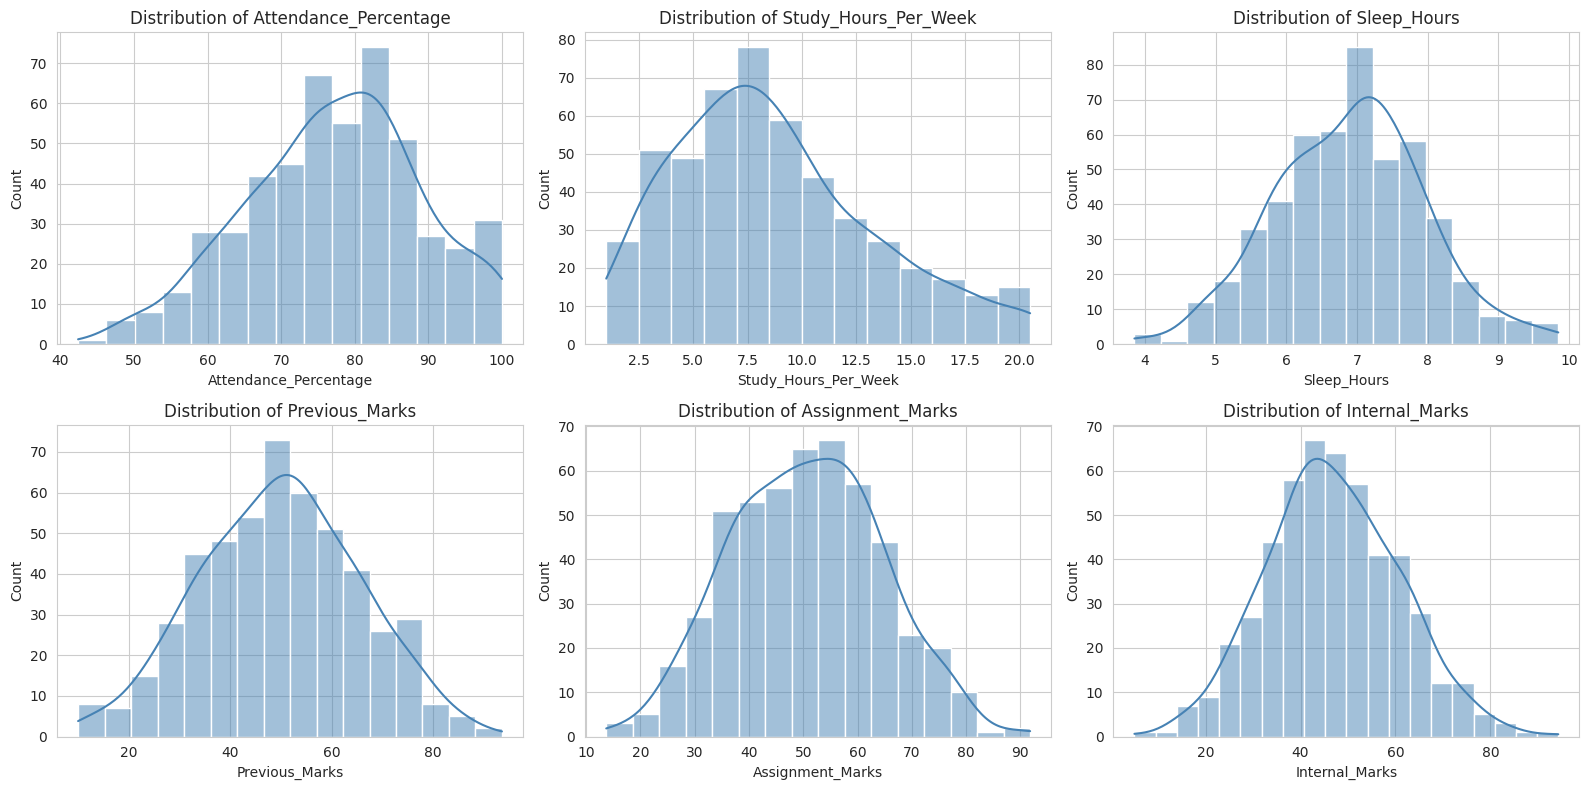

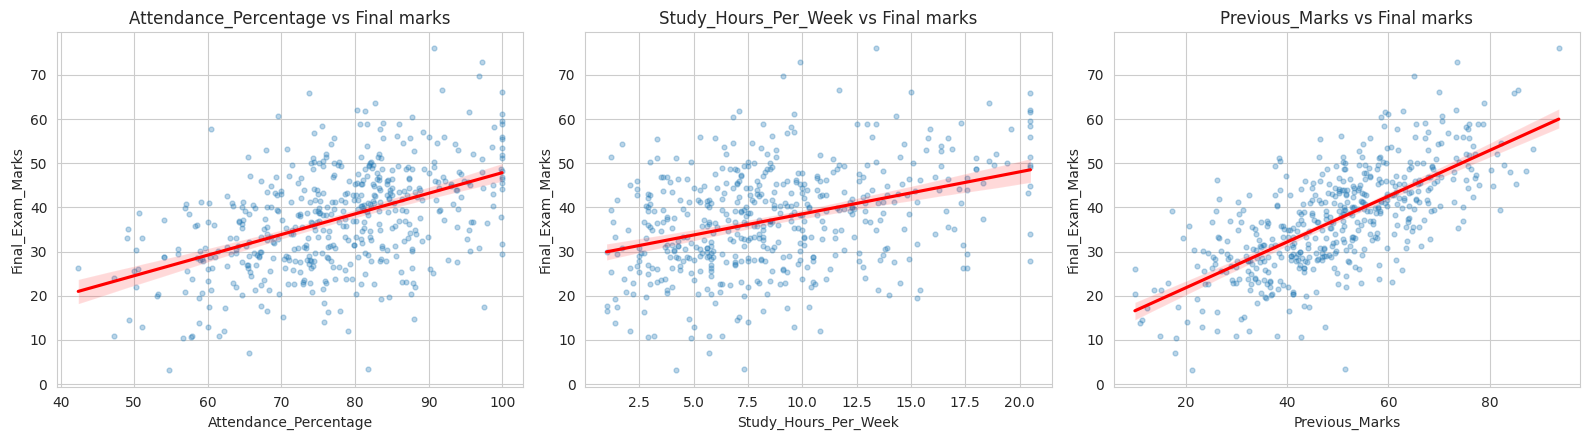

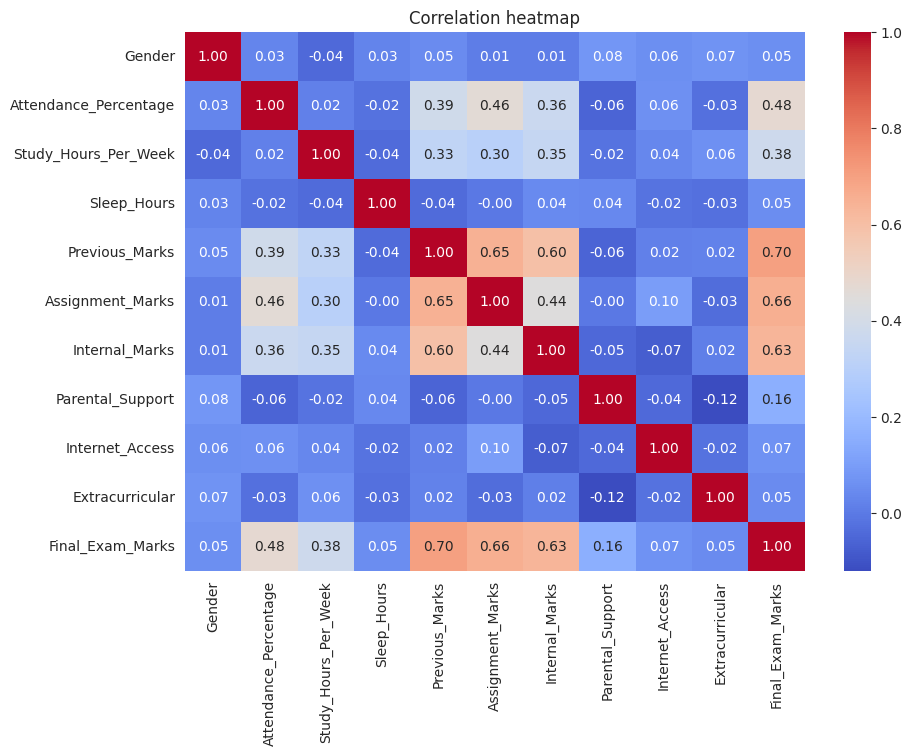

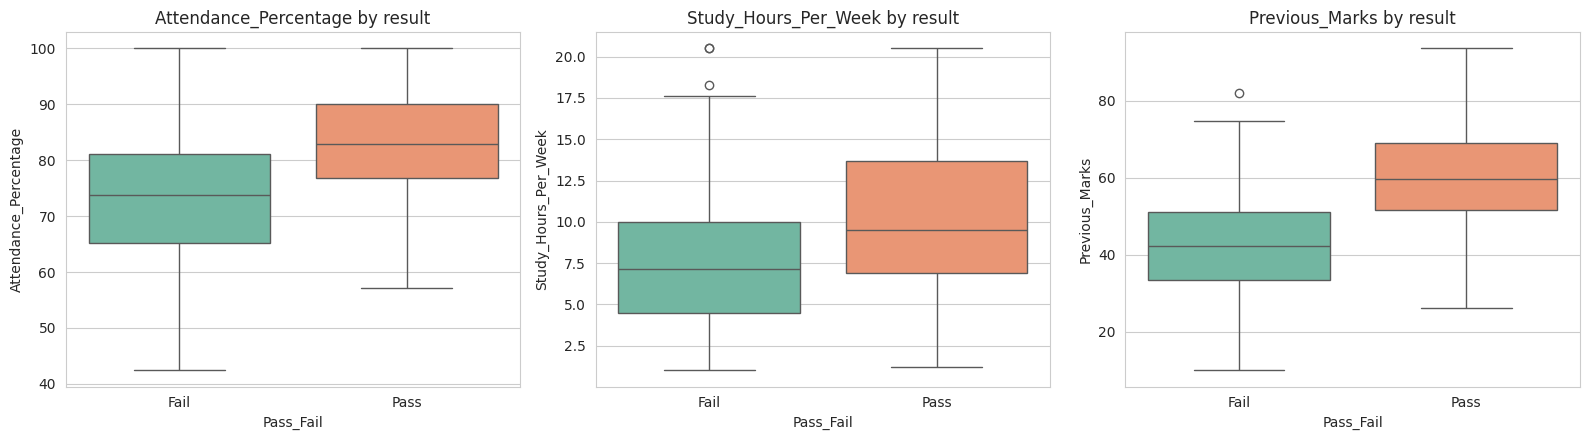

Correlation with Final_Exam_Marks:


,Final_Exam_Marks
Previous_Marks,0.699
Assignment_Marks,0.657
Internal_Marks,0.635
Attendance_Percentage,0.478
Study_Hours_Per_Week,0.377
Parental_Support,0.158
Internet_Access,0.067
Gender,0.055
Sleep_Hours,0.053
Extracurricular,0.049


In [ ]:
display(data.describe().T.round(2))
print("Pass:", data.Pass_Fail.sum(), "| Fail:", (data.Pass_Fail == 0).sum(),
      "| Pass rate: %.1f%%" % (100*data.Pass_Fail.mean()))

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(data[c], kde=True, ax=ax, color="steelblue"); ax.set_title(f"Distribution of {c}")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, c in zip(axes, ["Attendance_Percentage", "Study_Hours_Per_Week", "Previous_Marks"]):
    sns.regplot(x=c, y="Final_Exam_Marks", data=data, ax=ax, scatter_kws={"alpha": 0.3, "s": 12}, line_kws={"color": "red"})
    ax.set_title(f"{c} vs Final marks")
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(data.drop(columns="Pass_Fail").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, c in zip(axes, ["Attendance_Percentage", "Study_Hours_Per_Week", "Previous_Marks"]):
    sns.boxplot(x="Pass_Fail", y=c, data=data, ax=ax, palette="Set2"); ax.set_xticklabels(["Fail", "Pass"])
    ax.set_title(f"{c} by result")
plt.tight_layout(); plt.show()

print("Correlation with Final_Exam_Marks:")
display(data.drop(columns="Pass_Fail").corr()["Final_Exam_Marks"].drop("Final_Exam_Marks").sort_values(ascending=False).round(3))

Train: (400, 10) Test: (100, 10)
Linear Regression (test set)
  MAE  : 4.91 marks
  RMSE : 6.29 marks
  R2   : 0.6895
  5-fold CV R2: [0.6512 0.6863 0.6954 0.6547 0.5719] | mean = 0.6519


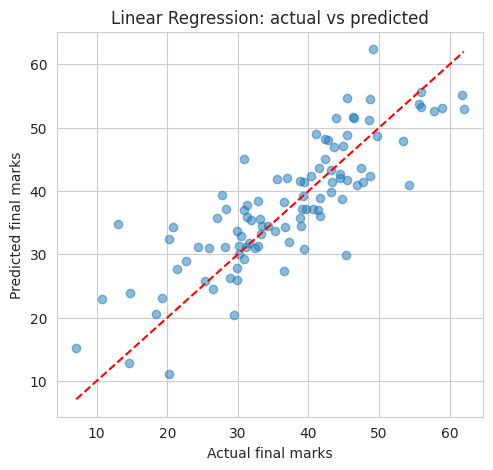

In [ ]:
# Final marks and Pass/Fail are NOT used as inputs (that would be target leakage)
FEATURES = [c for c in data.columns if c not in ["Final_Exam_Marks", "Pass_Fail"]]
X = data[FEATURES]
y_marks = data["Final_Exam_Marks"]
y_pass = data["Pass_Fail"]

X_train, X_test, ym_train, ym_test, yp_train, yp_test = train_test_split(
    X, y_marks, y_pass, test_size=0.20, random_state=RS, stratify=y_pass)
print("Train:", X_train.shape, "Test:", X_test.shape)

lin = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
lin.fit(X_train, ym_train)
pred = lin.predict(X_test)

print("Linear Regression (test set)")
print("  MAE  : %.2f marks" % mean_absolute_error(ym_test, pred))
print("  RMSE : %.2f marks" % np.sqrt(mean_squared_error(ym_test, pred)))
print("  R2   : %.4f" % r2_score(ym_test, pred))

cv_r2 = cross_val_score(lin, X_train, ym_train, cv=KFold(5, shuffle=True, random_state=RS), scoring="r2")
print("  5-fold CV R2:", np.round(cv_r2, 4), "| mean = %.4f" % cv_r2.mean())

plt.figure(figsize=(5.5, 5))
plt.scatter(ym_test, pred, alpha=0.5)
plt.plot([ym_test.min(), ym_test.max()], [ym_test.min(), ym_test.max()], "r--")
plt.xlabel("Actual final marks"); plt.ylabel("Predicted final marks"); plt.title("Linear Regression: actual vs predicted")
plt.show()

Logistic Regression (test set)
  Accuracy        : 0.8700
  Precision (Fail): 0.9091
  Recall (Fail)   : 0.8621
  F1 (Fail)       : 0.8850
  ROC-AUC         : 0.9475

              precision    recall  f1-score   support

        Fail       0.91      0.86      0.88        58
        Pass       0.82      0.88      0.85        42

    accuracy                           0.87       100
   macro avg       0.87      0.87      0.87       100
weighted avg       0.87      0.87      0.87       100



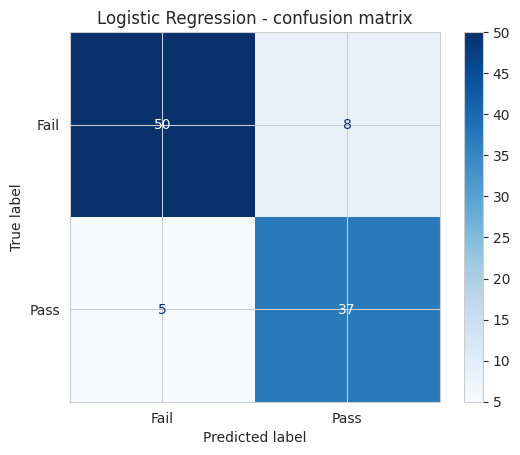

5-fold CV accuracy: [0.85   0.7375 0.8    0.7625 0.8375] | mean = 0.7975
5-fold CV ROC-AUC : [0.9124 0.8824 0.9073 0.8827 0.9065] | mean = 0.8982


In [ ]:
logi = Pipeline([("scaler", StandardScaler()),
                 ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RS))])
logi.fit(X_train, yp_train)
p_pred = logi.predict(X_test)
p_prob = logi.predict_proba(X_test)[:, 1]

def clf_report(name, y_true, y_hat, y_prob):
    print(f"{name} (test set)")
    print("  Accuracy        : %.4f" % accuracy_score(y_true, y_hat))
    print("  Precision (Fail): %.4f" % precision_score(y_true, y_hat, pos_label=0))
    print("  Recall (Fail)   : %.4f" % recall_score(y_true, y_hat, pos_label=0))
    print("  F1 (Fail)       : %.4f" % f1_score(y_true, y_hat, pos_label=0))
    print("  ROC-AUC         : %.4f" % roc_auc_score(y_true, y_prob))

clf_report("Logistic Regression", yp_test, p_pred, p_prob)
print()
print(classification_report(yp_test, p_pred, target_names=["Fail", "Pass"]))
ConfusionMatrixDisplay(confusion_matrix(yp_test, p_pred), display_labels=["Fail", "Pass"]).plot(cmap="Blues")
plt.title("Logistic Regression - confusion matrix"); plt.show()

skf = StratifiedKFold(5, shuffle=True, random_state=RS)
cv_acc = cross_val_score(logi, X_train, yp_train, cv=skf, scoring="accuracy")
cv_auc = cross_val_score(logi, X_train, yp_train, cv=skf, scoring="roc_auc")
print("5-fold CV accuracy:", np.round(cv_acc, 4), "| mean = %.4f" % cv_acc.mean())
print("5-fold CV ROC-AUC :", np.round(cv_auc, 4), "| mean = %.4f" % cv_auc.mean())

In [ ]:
knn = Pipeline([("scaler", StandardScaler()), ("model", KNeighborsClassifier(n_neighbors=5))])
knn.fit(X_train, yp_train)
k_pred = knn.predict(X_test); k_prob = knn.predict_proba(X_test)[:, 1]
clf_report("KNN (k=5)", yp_test, k_pred, k_prob)

# Find the 5 most similar students to one student
scaler_all = StandardScaler().fit(X)
nn = NearestNeighbors(n_neighbors=6).fit(scaler_all.transform(X))
student_idx = 0
dist, idx = nn.kneighbors(scaler_all.transform(X.iloc[[student_idx]]))
print("\nStudent being compared:", students.iloc[student_idx])
similar = data.iloc[idx[0][1:]][["Attendance_Percentage", "Study_Hours_Per_Week", "Previous_Marks", "Internal_Marks", "Final_Exam_Marks", "Pass_Fail"]].copy()
similar.insert(0, "Student_ID", students.iloc[idx[0][1:]].values)
similar["Distance"] = dist[0][1:].round(3)
print("Most similar students (similar academic pattern):")
display(data.iloc[[student_idx]][["Attendance_Percentage", "Study_Hours_Per_Week", "Previous_Marks", "Internal_Marks", "Final_Exam_Marks", "Pass_Fail"]])
display(similar)

KNN (k=5) (test set)
  Accuracy        : 0.8000
  Precision (Fail): 0.8393
  Recall (Fail)   : 0.8103
  F1 (Fail)       : 0.8246
  ROC-AUC         : 0.8828

Student being compared: STU0001
Most similar students (similar academic pattern):


,Attendance_Percentage,Study_Hours_Per_Week,Previous_Marks,Internal_Marks,Final_Exam_Marks,Pass_Fail
0,76.9,15.3,54.9,52.1,41.2,1


,Student_ID,Attendance_Percentage,Study_Hours_Per_Week,Previous_Marks,Internal_Marks,Final_Exam_Marks,Pass_Fail,Distance
21,STU0022,80.8,9.3,59.7,49.6,40.3,1,1.544
331,STU0332,81.1,11.6,53.0,51.5,39.9,0,1.825
337,STU0338,75.0,8.1,51.6,37.3,43.0,1,1.907
261,STU0262,69.4,11.7,51.4,40.0,39.4,0,1.930
341,STU0342,74.5,13.4,58.9,72.0,50.3,1,1.957


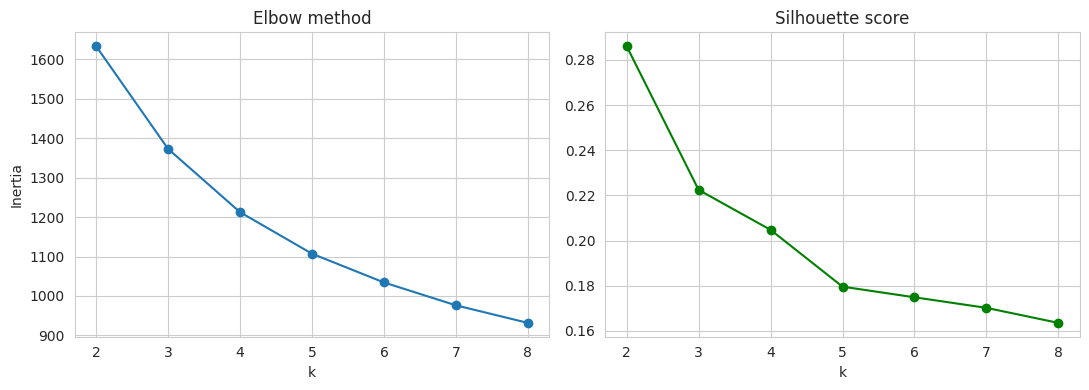

In [ ]:
CLUSTER_FEATS = ["Attendance_Percentage", "Study_Hours_Per_Week", "Previous_Marks", "Assignment_Marks", "Internal_Marks"]
Xc = StandardScaler().fit_transform(data[CLUSTER_FEATS])

inertia, sil = [], []
ks = range(2, 9)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RS).fit(Xc)
    inertia.append(km.inertia_); sil.append(silhouette_score(Xc, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(list(ks), inertia, "o-"); ax[0].set_title("Elbow method"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia")
ax[1].plot(list(ks), sil, "o-", color="green"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

Students per segment:
 Segment
At-Risk            207
Average            196
High Performing     97
Name: count, dtype: int64 



,Attendance_Percentage,Study_Hours_Per_Week,Previous_Marks,Assignment_Marks,Internal_Marks,Final_Exam_Marks,Pass_Fail
Segment,,,,,,,
High Performing,82.20,14.55,67.76,64.86,61.88,49.57,0.87
Average,83.93,7.02,54.28,55.12,49.71,40.29,0.55
At-Risk,68.79,7.56,37.26,39.81,37.06,28.71,0.09


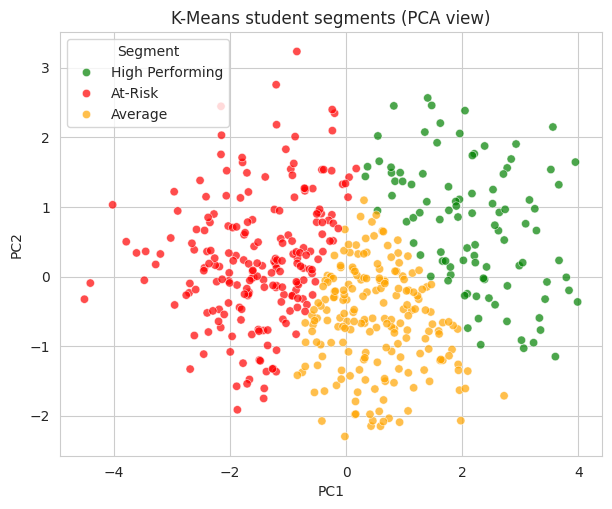

In [ ]:
# Three groups as required: High Performing, Average, At-Risk
kmeans_pipe = Pipeline([("scaler", StandardScaler()), ("km", KMeans(n_clusters=3, n_init=10, random_state=RS))])
data["Cluster"] = kmeans_pipe.fit_predict(data[CLUSTER_FEATS])

# Name the clusters by their average academic score (low -> At-Risk, high -> High Performing)
data["Academic_Score"] = data[["Attendance_Percentage", "Previous_Marks", "Assignment_Marks", "Internal_Marks"]].mean(axis=1)
order = data.groupby("Cluster")["Academic_Score"].mean().sort_values().index.tolist()
cluster_names = {order[0]: "At-Risk", order[1]: "Average", order[2]: "High Performing"}
data["Segment"] = data["Cluster"].map(cluster_names)

print("Students per segment:\n", data["Segment"].value_counts(), "\n")
profile = data.groupby("Segment")[CLUSTER_FEATS + ["Final_Exam_Marks", "Pass_Fail"]].mean().round(2)
display(profile.loc[["High Performing", "Average", "At-Risk"]])

pcs = PCA(n_components=2, random_state=RS).fit_transform(Xc)
plt.figure(figsize=(7, 5.5))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=data["Segment"], palette={"High Performing": "green", "Average": "orange", "At-Risk": "red"}, alpha=0.7)
plt.title("K-Means student segments (PCA view)"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()

In [ ]:
# --- Regression: compare Linear / Ridge / Lasso with tuned regularisation ---
kf = KFold(5, shuffle=True, random_state=RS)
reg_results = {}
for name, est, grid in [
    ("Linear Regression", LinearRegression(), {}),
    ("Ridge", Ridge(), {"model__alpha": [0.01, 0.1, 1, 10, 100]}),
    ("Lasso", Lasso(max_iter=10000), {"model__alpha": [0.001, 0.01, 0.1, 1]}),
]:
    gs = GridSearchCV(Pipeline([("scaler", StandardScaler()), ("model", est)]), grid or {"model__fit_intercept": [True]},
                      cv=kf, scoring="r2")
    gs.fit(X_train, ym_train)
    t = gs.predict(X_test)
    reg_results[name] = {"Best params": gs.best_params_, "CV R2": round(gs.best_score_, 4),
                         "Test R2": round(r2_score(ym_test, t), 4), "Test MAE": round(mean_absolute_error(ym_test, t), 3)}
    if name == "Linear Regression": best_reg_models = {}
    best_reg_models[name] = gs.best_estimator_
pd.set_option("display.max_colwidth", None)
display(pd.DataFrame(reg_results).T)

best_reg_name = max(reg_results, key=lambda n: reg_results[n]["CV R2"])
best_reg = best_reg_models[best_reg_name]
print("Best regression model:", best_reg_name)

,Best params,CV R2,Test R2,Test MAE
Linear Regression,{'model__fit_intercept': True},0.6519,0.6895,4.911
Ridge,{'model__alpha': 10},0.6534,0.6904,4.906
Lasso,{'model__alpha': 0.1},0.6537,0.6888,4.927


Best regression model: Lasso


Logistic Regression best params: {'model__C': 0.01} | CV ROC-AUC = 0.9034
KNN best params                : {'model__metric': 'manhattan', 'model__n_neighbors': 31, 'model__weights': 'uniform'} | CV ROC-AUC = 0.8895
Logistic Regression (tuned) (test set)
  Accuracy        : 0.8800
  Precision (Fail): 0.9259
  Recall (Fail)   : 0.8621
  F1 (Fail)       : 0.8929
  ROC-AUC         : 0.9458

KNN (tuned) (test set)
  Accuracy        : 0.8700
  Precision (Fail): 0.8689
  Recall (Fail)   : 0.9138
  F1 (Fail)       : 0.8908
  ROC-AUC         : 0.9421

Best classifier: Logistic Regression


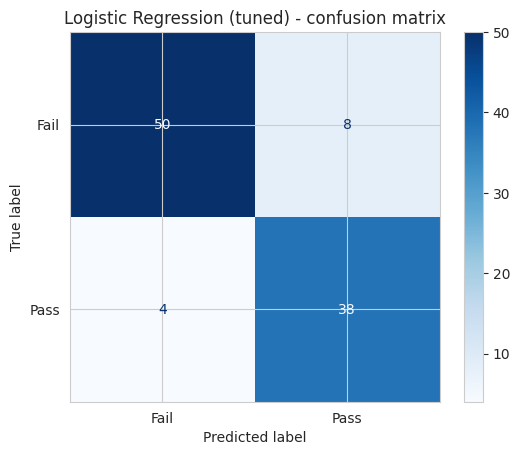

In [ ]:
# --- Classification: tune Logistic Regression and KNN ---
gs_log = GridSearchCV(Pipeline([("scaler", StandardScaler()),
                                ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RS))]),
                      {"model__C": [0.01, 0.1, 1, 10, 100]}, cv=skf, scoring="roc_auc").fit(X_train, yp_train)

gs_knn = GridSearchCV(Pipeline([("scaler", StandardScaler()), ("model", KNeighborsClassifier())]),
                      {"model__n_neighbors": list(range(3, 32, 2)), "model__weights": ["uniform", "distance"],
                       "model__metric": ["euclidean", "manhattan"]}, cv=skf, scoring="roc_auc").fit(X_train, yp_train)

print("Logistic Regression best params:", gs_log.best_params_, "| CV ROC-AUC = %.4f" % gs_log.best_score_)
print("KNN best params                :", gs_knn.best_params_, "| CV ROC-AUC = %.4f" % gs_knn.best_score_)

for name, gs in [("Logistic Regression (tuned)", gs_log), ("KNN (tuned)", gs_knn)]:
    clf_report(name, yp_test, gs.predict(X_test), gs.predict_proba(X_test)[:, 1]); print()

best_clf = gs_log.best_estimator_ if gs_log.best_score_ >= gs_knn.best_score_ else gs_knn.best_estimator_
best_clf_name = "Logistic Regression" if best_clf is gs_log.best_estimator_ else "KNN"
print("Best classifier:", best_clf_name)

ConfusionMatrixDisplay(confusion_matrix(yp_test, best_clf.predict(X_test)), display_labels=["Fail", "Pass"]).plot(cmap="Blues")
plt.title(f"{best_clf_name} (tuned) - confusion matrix"); plt.show()

,Student_ID,Actual_Marks,Predicted_Marks,Pass_Probability,Fail_Probability,Pass_Fail_Prediction,Risk_Level,Segment
0,STU0001,41.2,43.4,0.641,0.359,Pass,Medium,High Performing
1,STU0002,20.9,17.4,0.071,0.929,Fail,High,At-Risk
2,STU0003,21.3,26.0,0.178,0.822,Fail,High,At-Risk
3,STU0004,51.8,57.5,0.913,0.087,Pass,Low,High Performing
4,STU0005,26.8,19.1,0.084,0.916,Fail,High,At-Risk
5,STU0006,37.2,32.3,0.302,0.698,Fail,High,At-Risk
6,STU0007,66.2,61.3,0.943,0.057,Pass,Low,High Performing
7,STU0008,58.9,53.7,0.886,0.114,Pass,Low,High Performing
8,STU0009,22.0,35.3,0.407,0.593,Fail,Medium,At-Risk
9,STU0010,33.1,24.9,0.169,0.831,Fail,High,At-Risk


Risk level counts:
 Risk_Level
Low       105
Medium    187
High      208
Name: count, dtype: int64 

Risk_Level       Low  Medium  High
Segment                           
At-Risk            0      18   189
Average           27     150    19
High Performing   78      19     0


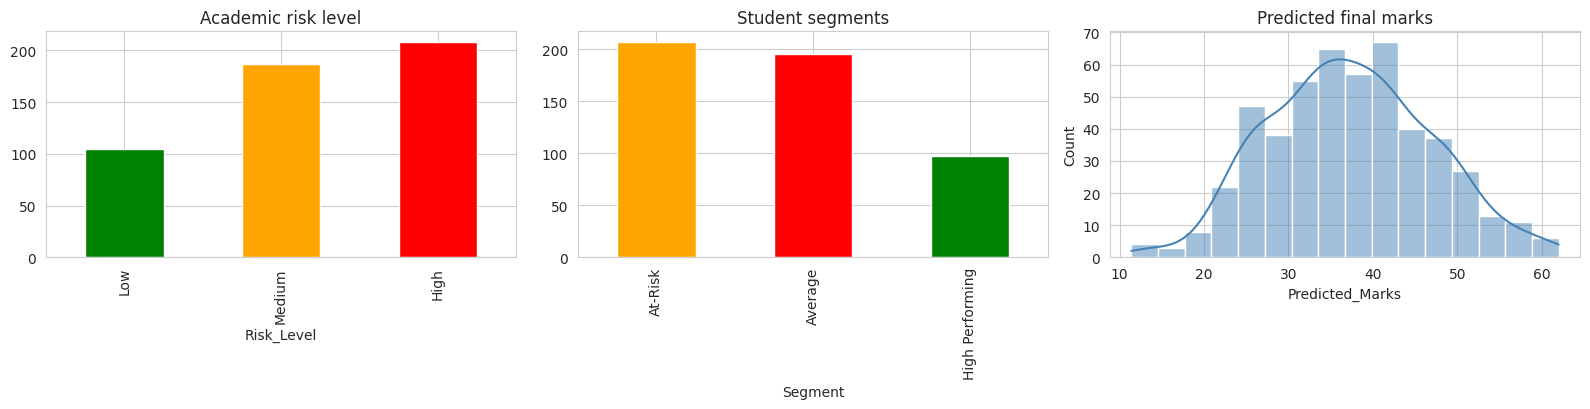


Students at HIGH academic risk (need early intervention):


,Student_ID,Actual_Marks,Predicted_Marks,Pass_Probability,Fail_Probability,Pass_Fail_Prediction,Risk_Level,Segment
141,STU0142,13.9,12.9,0.042,0.958,Fail,High,At-Risk
104,STU0105,20.3,11.4,0.042,0.958,Fail,High,At-Risk
392,STU0393,3.1,13.0,0.044,0.956,Fail,High,At-Risk
297,STU0298,14.6,13.5,0.045,0.955,Fail,High,At-Risk
358,STU0359,10.5,15.4,0.053,0.947,Fail,High,At-Risk
471,STU0472,7.1,15.0,0.065,0.935,Fail,High,At-Risk
1,STU0002,20.9,17.4,0.071,0.929,Fail,High,At-Risk
4,STU0005,26.8,19.1,0.084,0.916,Fail,High,At-Risk
302,STU0303,14.1,19.7,0.088,0.912,Fail,High,At-Risk
209,STU0210,16.3,19.6,0.089,0.911,Fail,High,At-Risk


Saved: student_risk_results.csv


In [ ]:
# Out-of-fold predictions for ALL students (each student is predicted by a model that did not train on them)
all_marks = cross_val_predict(best_reg, X, y_marks, cv=kf)
all_pass_prob = cross_val_predict(best_clf, X, y_pass, cv=skf, method="predict_proba")[:, 1]

def risk_level(p_fail):
    if p_fail < 0.30: return "Low"
    if p_fail < 0.60: return "Medium"
    return "High"

results = pd.DataFrame({
    "Student_ID": students.values,
    "Actual_Marks": y_marks.values,
    "Predicted_Marks": all_marks.round(1),
    "Pass_Probability": all_pass_prob.round(3),
    "Fail_Probability": (1 - all_pass_prob).round(3),
})
results["Pass_Fail_Prediction"] = np.where(results.Pass_Probability >= 0.5, "Pass", "Fail")
results["Risk_Level"] = results["Fail_Probability"].apply(risk_level)
results["Segment"] = data["Segment"].values

display(results.head(15))
print("Risk level counts:\n", results["Risk_Level"].value_counts().reindex(["Low", "Medium", "High"]), "\n")
print(pd.crosstab(results["Segment"], results["Risk_Level"]).reindex(columns=["Low", "Medium", "High"], fill_value=0))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
results["Risk_Level"].value_counts().reindex(["Low", "Medium", "High"]).plot(kind="bar", color=["green", "orange", "red"], ax=ax[0], title="Academic risk level")
results["Segment"].value_counts().plot(kind="bar", color=["orange", "red", "green"], ax=ax[1], title="Student segments")
sns.histplot(results["Predicted_Marks"], kde=True, ax=ax[2], color="steelblue"); ax[2].set_title("Predicted final marks")
plt.tight_layout(); plt.show()

print("\nStudents at HIGH academic risk (need early intervention):")
display(results[results["Risk_Level"] == "High"].sort_values("Fail_Probability", ascending=False).head(15))
results.to_csv("student_risk_results.csv", index=False)
print("Saved: student_risk_results.csv")

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))

lin_coef = pd.Series(best_reg.named_steps["model"].coef_, index=FEATURES).sort_values()
lin_coef.plot(kind="barh", ax=ax[0], color="steelblue", title="Marks model: standardised coefficients")

log_coef = pd.Series(gs_log.best_estimator_.named_steps["model"].coef_[0], index=FEATURES).sort_values()
log_coef.plot(kind="barh", ax=ax[1], color="seagreen", title="Pass/Fail model: coefficients (+ = helps pass)")

perm = permutation_importance(best_reg, X_test, ym_test, n_repeats=15, random_state=RS, scoring="r2")
pd.Series(perm.importances_mean, index=FEATURES).sort_values().plot(kind="barh", ax=ax[2], color="darkorange", title="Permutation importance (R2 drop)")
plt.tight_layout(); plt.show()

top = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)
print("Most important factors for final marks:")
for i, (f, v) in enumerate(top.head(5).items(), 1):
    print(f"  {i}. {f}  (importance = {v:.3f})")

In [ ]:
joblib.dump({"features": FEATURES, "regressor": best_reg, "classifier": best_clf,
             "kmeans": kmeans_pipe, "cluster_feats": CLUSTER_FEATS, "cluster_names": cluster_names},
            "student_models.joblib")
print("Saved: student_models.joblib")

bundle = joblib.load("student_models.joblib")

def predict_student(attendance, study_hours, sleep_hours, previous_marks, assignment_marks, internal_marks,
                    gender="Male", parental_support="Medium", internet="Yes", extracurricular="No"):
    row = pd.DataFrame([{
        "Gender": {"Male": 0, "Female": 1}[gender],
        "Attendance_Percentage": attendance, "Study_Hours_Per_Week": study_hours, "Sleep_Hours": sleep_hours,
        "Previous_Marks": previous_marks, "Assignment_Marks": assignment_marks, "Internal_Marks": internal_marks,
        "Parental_Support": {"Low": 0, "Medium": 1, "High": 2}[parental_support],
        "Internet_Access": {"No": 0, "Yes": 1}[internet],
        "Extracurricular": {"No": 0, "Yes": 1}[extracurricular],
    }])[bundle["features"]]
    marks = float(np.clip(bundle["regressor"].predict(row)[0], 0, 100))
    p_pass = float(bundle["classifier"].predict_proba(row)[0][1])
    seg = bundle["cluster_names"][int(bundle["kmeans"].predict(row[bundle["cluster_feats"]])[0])]
    print("\n===== Student Performance Prediction =====")
    print(f"Predicted final marks : {marks:.1f} / 100")
    print(f"Pass / Fail           : {'Pass' if p_pass >= 0.5 else 'Fail'}  (pass probability = {p_pass*100:.1f}%)")
    print(f"Academic risk level   : {risk_level(1 - p_pass)}")
    print(f"Performance segment   : {seg}")

# Example 1: strong student
predict_student(attendance=92, study_hours=22, sleep_hours=7, previous_marks=82, assignment_marks=85, internal_marks=80)
# Example 2: weak student
predict_student(attendance=55, study_hours=4, sleep_hours=5, previous_marks=38, assignment_marks=40, internal_marks=35,
                parental_support="Low", internet="No")

In [ ]:
# Enter your own student's details
def cli():
    a  = float(input("Attendance % (0-100): "))
    sh = float(input("Study hours per week: "))
    sl = float(input("Sleep hours per day: "))
    pm = float(input("Previous marks (0-100): "))
    am = float(input("Assignment marks (0-100): "))
    im = float(input("Internal marks (0-100): "))
    ps = input("Parental support (Low/Medium/High): ").strip().title()
    predict_student(a, sh, sl, pm, am, im, parental_support=ps)
cli()